# 01 · EDA — CC-News (`vblagoje/cc_news`)

708,241 English news articles, Jan 2017 – Dec 2019, extracted with news-please.
Columns: `title`, `text`, `domain`, `date`, `description`, `url`, `image_url`.

**Questions this notebook answers**
1. What does the data look like, and how clean is it (nulls, empties, duplicates, boilerplate)?
2. How is volume spread over time? Gaps, spikes, missing timestamps?
3. Which publishers dominate? How concentrated is the corpus?
4. Which outlets have **consistent coverage** across the whole window?
5. Which countries are the publishers from? (proxy: TLD + manual map)
6. Can we derive a **topic** label (URL section)?
7. How much wire copy (AP/Reuters/AFP) and cross-outlet duplication is there?
8. How long is a typical article per outlet and topic? (length targets for generation)
9. Summary: biases found + outlet shortlist for fine-tuning.
10. What is still missing (§12), cleaning and topic labelling (§13), chart fixes (§14).

Each output is followed by an **Interpretation** cell, written after the first full run. Re-check the numbers when the code changes.

## 0. Setup & load

In [3]:
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid')

SAMPLE = None      # e.g. 100_000 for a fast first pass; None = full dataset
TOP_N = 30         # how many publishers to show in per-outlet plots
OUT = Path('../data/interim')
OUT.mkdir(parents=True, exist_ok=True)

Chart defaults used from here on (see §14): thousands separators, no top/right spines, and a `save()` helper that writes figures for the written report.

In [ ]:
import matplotlib.ticker as mtick

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
})
FIG = Path('../reports/figures')
FIG.mkdir(parents=True, exist_ok=True)
thousands = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')
ACCENT, MUTED = '#2a6fdb', '#c9ced6'

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')

In [4]:
ds = load_dataset('vblagoje/cc_news', split='train')
if SAMPLE:
    ds = ds.shuffle(seed=42).select(range(SAMPLE))
df = ds.to_pandas()
df.shape

Generating train split: 100%|██████████| 708241/708241 [00:04<00:00, 159962.18 examples/s]


(708241, 7)

## 1. Structure
Schema, dtypes, memory, and missing values. Empty strings count as missing too (news-please often returns `''` instead of null).

In [5]:
df.info(memory_usage='deep')
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708241 entries, 0 to 708240
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   title        708241 non-null  object
 1   text         708241 non-null  object
 2   domain       708241 non-null  object
 3   date         708241 non-null  object
 4   description  708241 non-null  object
 5   url          708241 non-null  object
 6   image_url    708241 non-null  object
dtypes: object(7)
memory usage: 3.3 GB


,title,text,domain,date,description,url,image_url
0,Daughter Duo is Dancing in The Same Company,There's a surprising twist to Regina Willoughby's last season with Columbia City Ballet: It's also her 18-year-old d...,www.pointemagazine.com,2017-12-11 20:19:05,There's a surprising twist to Regina Willoughby's last season with Columbia City Ballet: It's also her 18-year-old d...,http://www.pointemagazine.com/mother-daughter-duo-dancing-2516681965.html,https://pointe-img.rbl.ms/simage/https%3A%2F%2Fassets.rbl.ms%2F16807693%2F980x.png/2000%2C2000/3VnhNGWp75K4SwMx/img.png
1,New York City Ballet Announces Interim Leadership Team,The New York City Ballet Board of Directors announced on Saturday the interim team that has been appointed to run th...,www.pointemagazine.com,2017-12-11 17:02:55,NYCB has announced an interim leadership team to run the company during Peter Martin's leave of absence amidst sexua...,http://www.pointemagazine.com/nycb-interim-leadership-team-2516618703.html,https://pointe-img.rbl.ms/simage/https%3A%2F%2Fassets.rbl.ms%2F16802226%2F980x.jpg/2000%2C2000/ShYo5fi9RpsI65MR/img.jpg
2,Watch Pennsylvania Ballet & Boston Ballet Face Off for the Super Bowl,The Philadelphia Eagles and the New England Patriots aren't the only teams bringing Super Bowl entertainment this we...,www.pointemagazine.com,2018-02-02 21:58:13,The Philadelphia Eagles and the New England Patriots aren't the only teams bringing Super Bowl entertainment this we...,http://www.pointemagazine.com/watch-pennsylvania-ballet-boston-ballet-face-off-for-the-super-bowl-2530816257.html,https://pointe-img.rbl.ms/simage/https%3A%2F%2Fassets.rbl.ms%2F17154326%2F980x.png/2000%2C2000/TJRZyIfKyEmkrAwU/img.png
3,dance shoes,"Looking for your next audition shoe? Shot at and in collaboration with Broadway Dance Center, Só Dança has launched ...",www.pointemagazine.com,2018-04-24 19:00:11,"Looking for your next audition shoe? Shot at and in collaboration with Broadway Dance Center, Só Dança has launched ...",https://www.pointemagazine.com/dance-shoes-2562960796.html,https://pointe-img.rbl.ms/simage/https%3A%2F%2Fassets.rbl.ms%2F17590823%2F1200x600.jpg/2000%2C2000/vQLjf7MB8teU10V1/...
4,Rebecca Krohn on Her Retirement from New York City Ballet,New York City Ballet principal dancer Rebecca Krohn will take her final bow with the company this Saturday night. Kr...,www.pointemagazine.com,2017-10-06 14:44:51,"We interviewed New York City Ballet principal Rebecca Krohn on her company retirement, exciting new career as a ball...",http://www.pointemagazine.com/rebecca-krohn-retirement-nycb-2493308072.html,https://pointe-img.rbl.ms/simage/https%3A%2F%2Fassets.rbl.ms%2F11537098%2F980x.jpg/2000%2C2000/b0JqtcOZjNJndl99/img.jpg


**Interpretation.** 708,241 rows × 7 columns, all stored as text (`object`), 3.3 GB in memory. No column has real nulls, but empty strings hide behind that (next cell). `date` is a string and has to be parsed. Memory: the derived columns roughly double the footprint, so use `SAMPLE` while iterating.

In [6]:
missing = pd.DataFrame({
    'null': df.isna().sum(),
    'empty': df.apply(lambda s: s.fillna('').astype(str).str.strip().eq('')).sum(),
})
missing['pct_missing'] = (missing.sum(axis=1) / len(df) * 100).round(2)
missing

,null,empty,pct_missing
title,0,331,0.05
text,0,0,0.00
domain,0,0,0.00
date,0,77598,10.96
description,0,180574,25.50
url,0,0,0.00
image_url,0,0,0.00


**Interpretation.**
- `date` is empty in **77,598 rows (11.0%)**. Those articles can't be used for date conditioning → drop them (§13).
- `description` is empty in 25.5% → too patchy for a prompt feature.
- `title` empty in 331 rows (negligible). `text`, `url`, `domain`, `image_url` are always filled.

In [7]:
# A few random full rows, to eyeball what the text actually looks like
for _, r in df.sample(3, random_state=0).iterrows():
    print(r['domain'], '|', r['date'], '|', r['title'])
    print(r['text'][:800], '\n', '-' * 80)

lbccvikingnews.com | 2017-06-14 00:00:00 | Outfielder Ezequiel Carrera joins Jays' injury wing
After Ezequiel Carrera fouled a ball off his right foot during the Blue Jays’ 8-1 loss to the Tampa Bay Rays on Tuesday, the outfielder stumbled out of the batter’s box, hobbling briefly before returning to the plate for a strikeout.A day later, Carrera was once again hobbling, this time on crutches, his foot in a walking boot. It turns out the seemingly innocuous incident was more serious than originally thought. Toronto put Carrera on the 10-day disabled list Wednesday with a fracture in the top of his right foot. That makes 16 Blue Jays players forced to the sidelines this season; Carrera’s stint on the DL is the 20th for the team. Collectively, players have missed 478 games to injury. The Jays had spent 574 days on the disabled list before Carrera’s injury, according to spotrac.com, fo 
 --------------------------------------------------------------------------------
www.americanthinker.c

**Interpretation.** These three random rows already show three cleaning problems:
1. **Glued paragraphs:** "…for a strikeout.A day later". The extraction dropped line breaks between paragraphs, so paragraph counts are unreliable for some outlets.
2. **Title repeated as the first line** of the text (americanthinker.com).
3. **Auto-generated content:** chaffeybreeze.com is a templated stock-rating page ("reaffirmed their buy rating… (NASDAQ:MTSI)"). That isn't journalism and has to be flagged.

The `00:00:00` timestamps also appear here (see §3).

## 2. Data quality
- Exact duplicates (url, title, text)
- Length distribution: very short texts are often paywall stubs or extraction failures
- Boilerplate: repeated openings or endings (cookie banners, "Subscribe to…")

In [8]:
dups = {
    'url': df['url'].duplicated().sum(),
    'title': df['title'].duplicated().sum(),
    'text': df['text'].duplicated().sum(),
    'domain+title': df.duplicated(['domain', 'title']).sum(),
}
pd.Series(dups, name='n_duplicates').to_frame().assign(pct=lambda d: (d.n_duplicates / len(df) * 100).round(2))

,n_duplicates,pct
url,0,0.00
title,156534,22.10
text,141437,19.97
domain+title,51488,7.27


**Interpretation.** No URL is repeated, but **20% of texts and 22% of titles are duplicates**. 7.3% are the same title from the same outlet (pages republished or updated). The rest are the same text on different domains (syndication). → Deduplicate on the cleaned text before any sampling. That alone removes about a fifth of the corpus.

In [9]:
df['n_chars'] = df['text'].str.len()
df['n_words'] = df['text'].str.split().str.len()
df['title_words'] = df['title'].str.split().str.len()

df[['n_chars', 'n_words', 'title_words']].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])

,n_chars,n_words,title_words
count,708241.000000,708241.000000,708241.000000
mean,2387.462786,396.812647,9.542442
std,2828.520414,468.508775,3.552037
min,57.000000,15.000000,0.000000
1%,111.000000,19.000000,2.000000
5%,199.000000,33.000000,4.000000
25%,755.000000,125.000000,7.000000
50%,1744.000000,291.000000,9.000000
75%,3170.000000,527.000000,11.000000
95%,6388.000000,1061.000000,16.000000


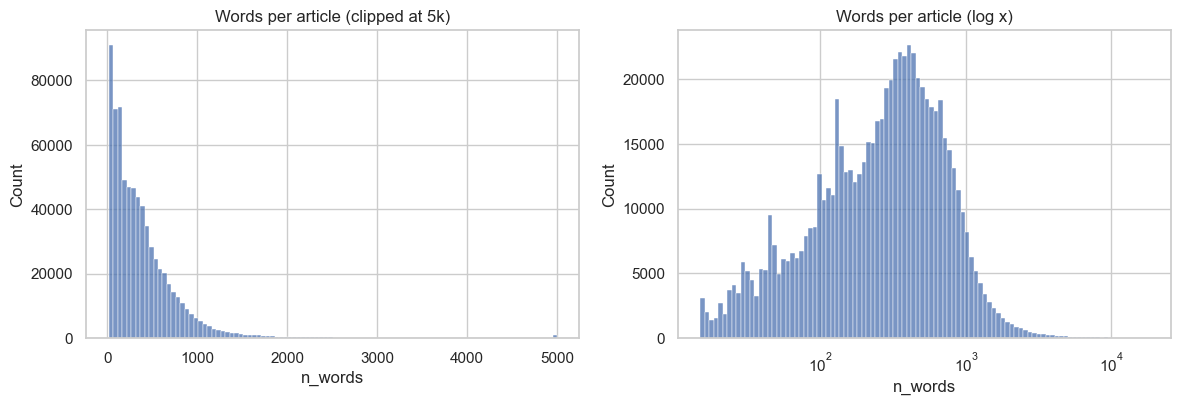

< 50 words: 0.0963 | > 5000 words: 0.0012


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['n_words'].clip(upper=5000), bins=100, ax=ax[0]).set(title='Words per article (clipped at 5k)')
sns.histplot(df['n_words'], bins=100, log_scale=True, ax=ax[1]).set(title='Words per article (log x)')
plt.show()

print('< 50 words:', (df.n_words < 50).mean().round(4), '| > 5000 words:', (df.n_words > 5000).mean().round(4))

**Interpretation.** Median 291 words, mean 397, long right tail (max 18k). 9.6% of rows have **< 50 words**. On the log scale the distribution has two peaks: a small one around 30–60 words (stubs, navigation pages, pages that are only boilerplate) and the main one around 300–600 words (real articles). → Minimum-length filter around 100 words.

**Chart:** the left panel adds little (spike at 0, pile-up at the 5k clip). Keep only the log-x panel, and add vertical lines at the median and at the 50/100-word thresholds.

In [11]:
# Inspect the extremes
df.loc[df.n_words < 50, ['domain', 'title', 'text']].sample(10, random_state=0)

,domain,title,text
268754,www.alquds.co.uk,الجيش التركي يدمر مخابئ لحزب العمال الكردستاني شمالي العراق,Send to Email Address\nYour Name\nYour Email Address\nPost was not sent - check your email addresses!\nEmail check f...
640433,www.crainsnewyork.com,Crain's New York Business,Get Crain's Video Report\nSign up for our FREE weekly Video Report email newsletter. A roundup of the latest video r...
645857,www.fox.com,Brooklyn Nine-Nine,Jake surprises Amy with a case about arsons that are committed by her favorite crossword puzzle author.
268520,www.alquds.co.uk,شركة عقارات قطرية تحصل على الموافقة لبناء ألف منزل في لندن,Send to Email Address\nYour Name\nYour Email Address\nPost was not sent - check your email addresses!\nEmail check f...
268683,www.alquds.co.uk,تأهل كارولينا بليسكوفا وفينوس وليامز إلى الدور الثالث,Send to Email Address\nYour Name\nYour Email Address\nPost was not sent - check your email addresses!\nEmail check f...
550206,nbc4i.com,Komen Columbus Race for the Cure,"Whether you drive around town or travel around the world, the information you’ll find here will make your journey sa..."
600744,www.topix.com,Luxury Overboard,Maybe it was the rendition of La Traviata during the ship's opera highlights show. Maybe it was the dinner of lobste...
680114,azlenews.net,Local youth wrestlers win Azle tourney,"If Javascript is disabled browser, to place orders please visit the page where I sell my photos, powered by Fotomoto."
528782,www.huffingtonpost.co.uk,UK Weather Forecast Live: Full School Snow Closures And Traffic Updates,Britain faces travel chaos this morning as the weekend’s snowfall turns to ice.\nYellow weather warnings for ice hav...
701481,www.cnn.com,Full Interview: Rep. Ron DeSantis,Rep. Ron DeSantis recounts the conversation he had with the shooter shortly before he opened fire on the congression...


**Interpretation.** The < 50-word rows are mostly not articles: Arabic headlines from alquds.co.uk whose text is an English share widget, newsletter sign-up boxes (Crain's), TV-episode blurbs (fox.com), photo-shop notices. This confirms the length filter and the need for a non-English title check (§13).

In [12]:
# Boilerplate: most frequent first/last 80 characters
print(df['text'].str[:80].value_counts().head(15), '\n')
print(df['text'].str[-80:].value_counts().head(15))

text
Get daily updates directly to your inbox + Subscribe Thank you for subscribing!        6608
We always recommend that before selecting or making any important decisions abou       2991
Cookies at Which? We use cookies to help improve our sites. If you continue, we'       2862
Get Daily updates directly to your inbox + Subscribe Thank you for subscribing!        2589
Read the latest and breaking Hindi news on amarujala.com. Get live Hindi news ab       2238
Send to Email Address\nYour Name\nYour Email Address\nPost was not sent - check you    2185
The video will start in 8 Cancel\nGet daily updates directly to your inbox + Subs      1973
UPDATE 3-Nestle takes food price rises in its stride\nZURICH, Aug 9 Nestle expect      1841
Read the latest and breaking news on amarujala.com. Get live Hindi news about In       1124
The video will start in 8 Cancel\nGet Daily updates directly to your inbox + Subs      1082
Thank you for submitting a review! Your input is very much appreciated. Sha

**Interpretation.** The most frequent openings and endings are boilerplate, each repeated thousands of times:
- Newsletter prompts ("Get daily updates directly to your inbox…": about 12k rows across its variants, probably Reach plc titles such as the Mirror and Express)
- Which?'s cookie banner (2,862)
- amarujala.com's Hindi-news promo (about 3.4k: the whole outlet)
- WordPress share widgets and social-button lists
- Investment disclaimers
- 1,841 identical copies of one Reuters story ("UPDATE 3-Nestle…")

The top ending, "*This material may not be published, broadcast, rewritten or redistributed*" (about 7k), is the **Associated Press copyright footer**. That is a wire marker, and the §9 wire regex misses it.

→ Strip known boilerplate before computing anything per outlet, or the model will learn it as the outlet's "style". Add the AP footer to wire detection.

## 3. Dates
- Parse failures and out-of-window dates (before 2017 / after 2019)
- Volume per month, day, weekday, hour
- Timestamps at exactly `00:00:00` probably mean *time unknown*, not midnight
- Spike days: news events, or crawler bursts?

In [13]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

print('unparseable:', df['date'].isna().sum())
print('range:', df['date'].min(), '->', df['date'].max())
print('outside 2017-2019:', (~df['date'].dt.year.between(2017, 2019)).sum())

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.to_period('M')
df['day'] = df['date'].dt.floor('D')

unparseable: 77598
range: 2017-01-01 00:00:00 -> 2019-08-25 20:17:00
outside 2017-2019: 77598


**Interpretation.** 77,598 dates are empty (the empty strings from §1). The "outside 2017–2019: 77598" line is a **bug**: `between()` returns False for missing dates, so it counts the same empty rows. In fact no dated article falls outside 2017–2019. The range runs to 2019-08-25, but the next charts show that real coverage ends in July 2018.

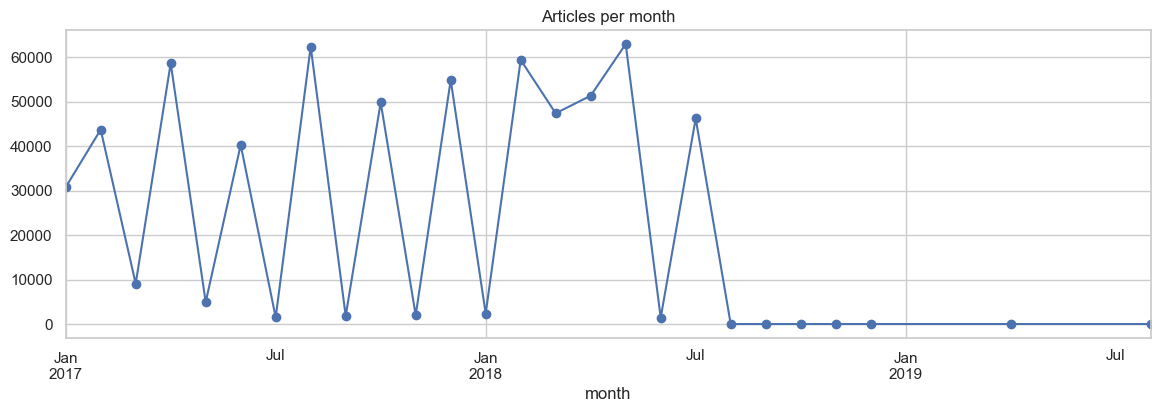

year
2017.0    359647
2018.0    270994
2019.0         2
Name: count, dtype: int64

In [14]:
monthly = df.groupby('month').size()
monthly.plot(figsize=(14, 4), marker='o', title='Articles per month')
plt.show()

df['year'].value_counts().sort_index()

**Interpretation.** This is **not a continuous time series**. Months alternate between 40–63k articles and under 3k, and from August 2018 to 2019 there are only 9 articles in total. → The usable window is **Jan 2017 – Jul 2018** (19 months), of which 13 months have ≥ 5k articles.

**Chart:** a line joining the months suggests a trend that isn't there. Use bars, highlight the snapshot months, and cut the 2018-08+ stragglers (example in §14).

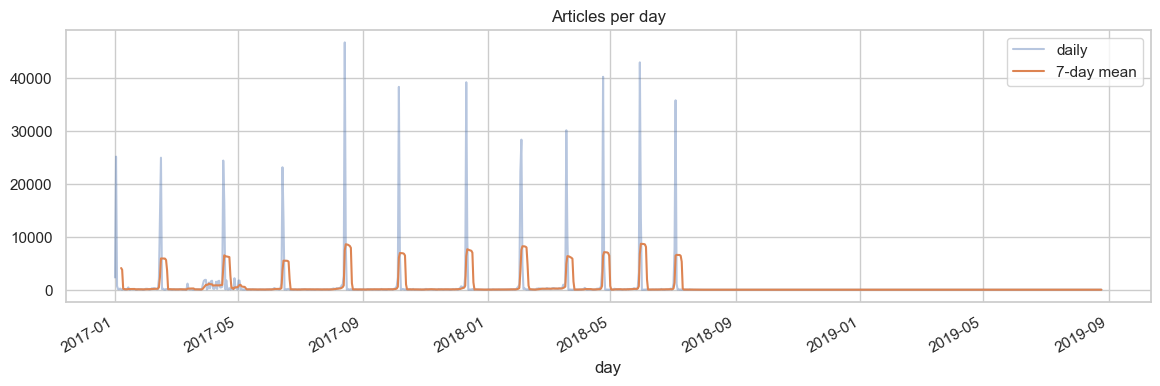

day
2017-08-14    46692
2018-05-30    42926
2018-04-24    40202
2017-12-11    39169
2017-10-06    38297
2018-07-04    35764
2018-03-19    30100
2018-02-03    28331
2017-01-02    25127
2017-02-15    24926
2017-04-17    24383
2017-06-14    23117
2018-02-02    22249
2017-04-18    16410
2017-02-14    13771
dtype: int64

In [16]:
daily = df.groupby('day').size()
ax = daily.plot(figsize=(14, 4), alpha=.4, label='daily')
daily.rolling(7).mean().plot(ax=ax, label='7-day mean')
ax.set_title('Articles per day'); ax.legend()
plt.show()

# Top spike days: check what happened on them
daily.sort_values(ascending=False).head(15)

**Interpretation.** The volume sits on about 12 spike days. The top 15 days hold about 451k articles, **72% of all dated articles**. Each spike is one Common Crawl news snapshot: the dataset is about a dozen crawls, not a daily feed.

Consequences:
- The **date** condition is in practice a choice among about 12 periods. Events between snapshots are missing from training.
- Date-leakage tests and test dates should be placed at snapshot dates.
- Per-outlet volume depends on whether the crawler hit the outlet on those days.

**Chart:** use a log y-axis (or one bar per day) and label the snapshot dates. The 7-day mean adds little.

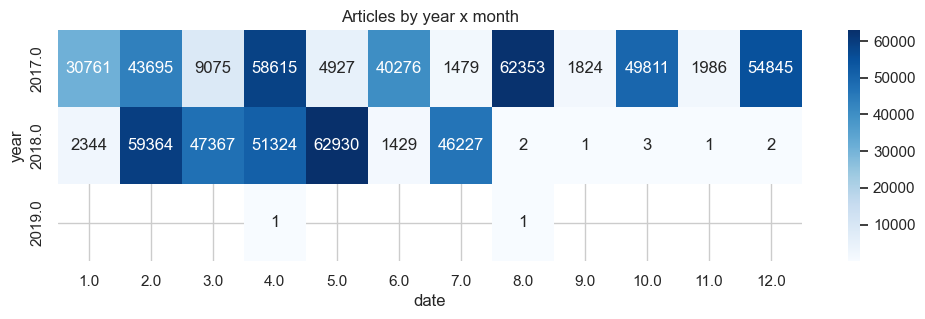

In [17]:
# Year x month heatmap
ym = df.pivot_table(index='year', columns=df['date'].dt.month, values='url', aggfunc='count')
plt.figure(figsize=(12, 3))
sns.heatmap(ym, annot=True, fmt='.0f', cmap='Blues')
plt.title('Articles by year x month')
plt.show()

**Interpretation.** Same picture by month: 13 months with 9k–63k articles, the rest under 5k. 2019 has 2 articles.

**Chart:** the labels are floats (`2017.0`, `1.0`) because missing dates turned year and month into float columns. Drop the missing dates and cast to `int`, use month names, show values in thousands (`fmt=',.0f'`), and drop the 2019 row.

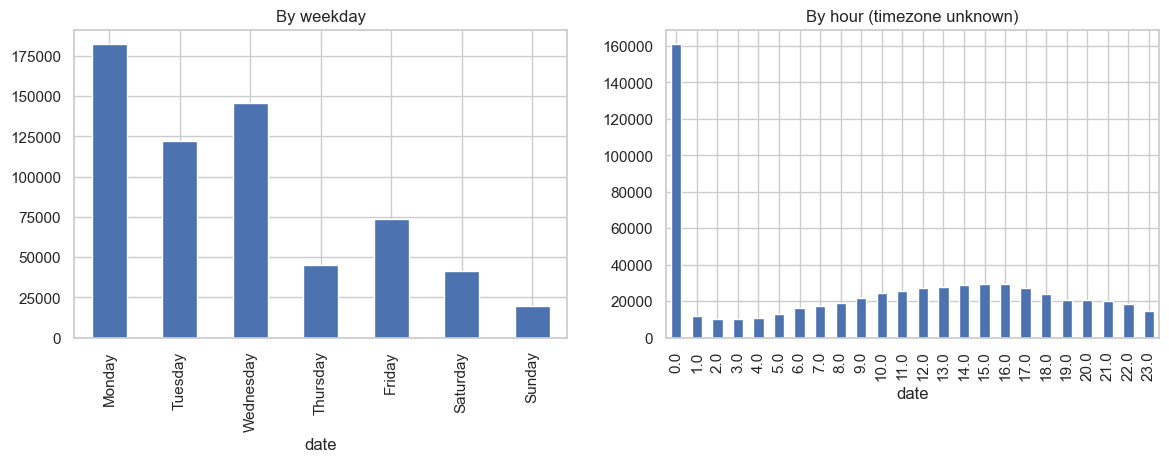

share with time exactly 00:00:00: 0.2057


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df['date'].dt.day_name().value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
).plot.bar(ax=ax[0], title='By weekday')
df['date'].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title='By hour (timezone unknown)')
plt.show()

midnight = (df['date'].dt.hour.eq(0) & df['date'].dt.minute.eq(0) & df['date'].dt.second.eq(0))
print('share with time exactly 00:00:00:', midnight.mean().round(4))

**Interpretation.**
- **Weekday** reflects which weekday each crawl snapshot fell on (Monday/Wednesday peaks), not publishing habits. It is not interpretable here.
- **Hour:** 20.6% of timestamps are exactly `00:00:00`, meaning the time is unknown. Without those, the curve is a normal daytime shape peaking around 13–16h (timezone unknown).

→ Condition on the date only, never on the time.

**Chart:** drop the unknown-time rows from the hour plot and use integer tick labels. Drop the weekday plot, or compute it within snapshots.

## 4. Publishers (`domain`)
- Normalize domains (lowercase, strip `www.`), and check `domain` against the host in `url`
- Number of publishers, top N, long tail
- Concentration: top-10/50/100 share, Gini, cumulative share curve

In [19]:
df['domain'] = df['domain'].str.lower().str.removeprefix('www.')
df['url_host'] = df['url'].map(lambda u: urlparse(u).netloc.lower().removeprefix('www.'))
print('domain != url host:', (df['domain'] != df['url_host']).sum())
df.loc[df['domain'] != df['url_host'], ['domain', 'url_host']].drop_duplicates().head(20)

domain != url host: 64


,domain,url_host
48893,leaderlive.co.uk,leaderlive.co.uk:80
192771,countytimes.co.uk,countytimes.co.uk:80
232828,wellbeinghi.com,wellbeinghi.com:80
282339,rhyljournal.co.uk,rhyljournal.co.uk:80
353524,rotherhamadvertiser.co.uk,rotherhamadvertiser.co.uk:80
457997,chesterstandard.co.uk,chesterstandard.co.uk:80
482471,bordercountiesadvertizer.co.uk,bordercountiesadvertizer.co.uk:80
518910,northwalespioneer.co.uk,northwalespioneer.co.uk:80
568138,artforum.com,artforum.com:443
591919,air.mozilla.org,air.mozilla.org:443


**Interpretation.** Only 64 mismatches. All are port numbers in the URL host (`:80`, `:443`), plus one raw IP host. Harmless. The real publisher problem is **subdomains of the same outlet** (uk.reuters.com, in.reuters.com, reuters.com; bbc.co.uk, bbc.com), which have to be merged into one `publisher` (§13).

unique publishers: 8586
count     8586.000000
mean        82.487887
std        442.366279
min          1.000000
25%          3.000000
50%         12.000000
75%         50.000000
max      24480.000000
Name: count, dtype: float64
publishers with >= 100 articles: 1276
publishers with >= 1000 articles: 96
publishers with >= 5000 articles: 5
publishers with >= 10000 articles: 4


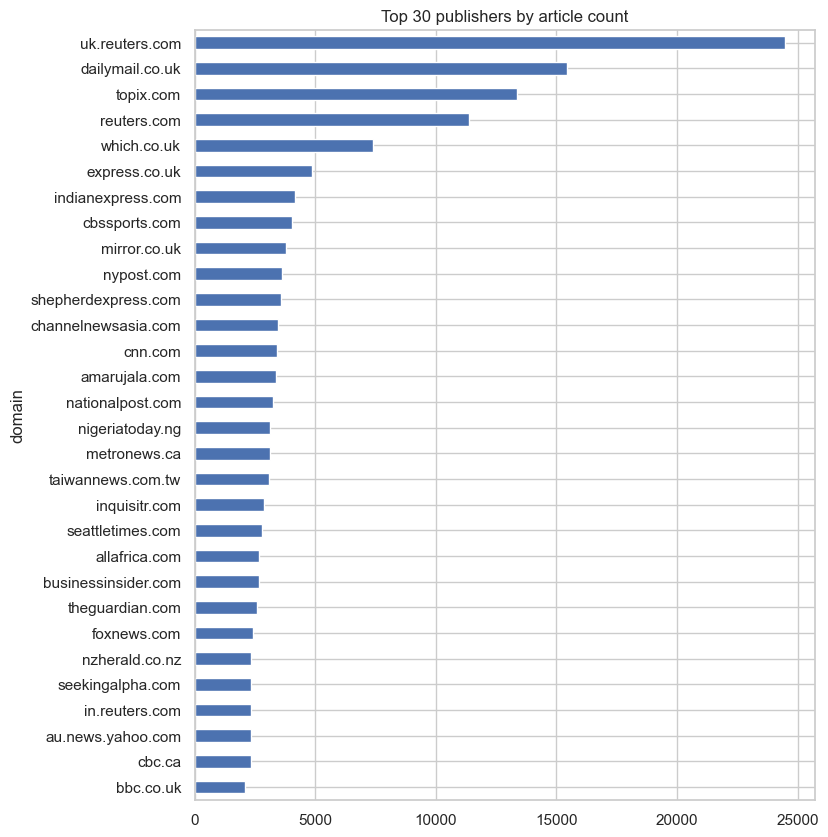

In [20]:
per_domain = df['domain'].value_counts()
print('unique publishers:', per_domain.size)
print(per_domain.describe())
for k in [100, 1000, 5000, 10000]:
    print(f'publishers with >= {k} articles:', (per_domain >= k).sum())

per_domain.head(TOP_N).sort_values().plot.barh(figsize=(8, 10), title=f'Top {TOP_N} publishers by article count')
plt.show()

**Interpretation.**
- **8,586 publishers**, median 12 articles each. Only **96 have ≥ 1,000** and 5 have ≥ 5,000.
- Reuters spread over 3 subdomains is the largest outlet: 38,190 articles (5.4%).
- Several top "publishers" are not newsrooms:
  - topix.com: aggregator snippets
  - which.co.uk: consumer product directory
  - amarujala.com: Hindi site, only boilerplate text
  - cbssports.com: mostly fantasy-sports blurbs

→ After cleaning, few outlets will have more than about 2k articles. **1–2k per outlet is the realistic ceiling** for balanced sampling.

**Chart:** merge subdomains first, annotate the counts, and colour the bars by kept/dropped or by country (example in §14).

{'top_1_share': 0.035, 'top_10_share': 0.131, 'top_50_share': 0.262, 'top_100_share': 0.352}
Gini: 0.825


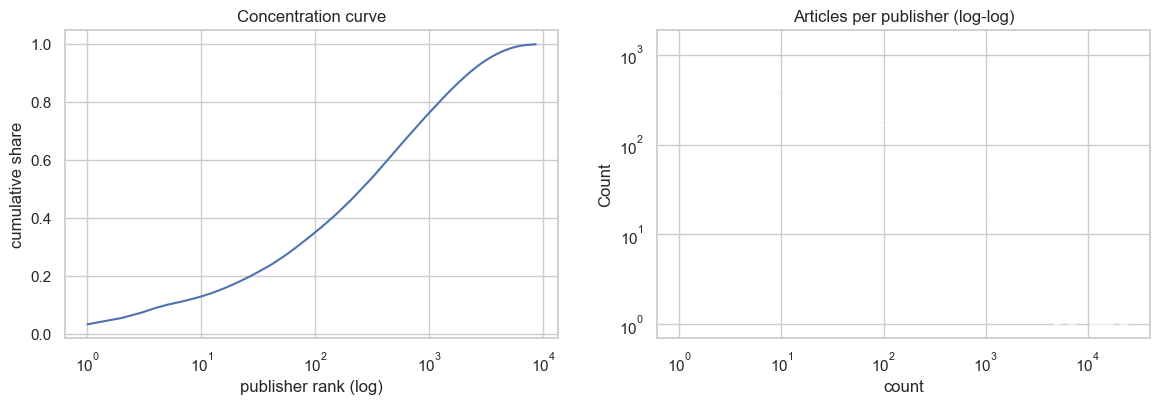

In [21]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return ((2 * np.arange(1, n + 1) - n - 1) @ x) / (n * x.sum())

share = per_domain / per_domain.sum()
print({f'top_{k}_share': round(share.head(k).sum(), 3) for k in [1, 10, 50, 100]})
print('Gini:', round(gini(per_domain), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(np.arange(1, len(share) + 1), share.cumsum().values)
ax[0].set(xscale='log', xlabel='publisher rank (log)', ylabel='cumulative share', title='Concentration curve')
sns.histplot(per_domain, bins=60, log_scale=(True, True), ax=ax[1]).set(title='Articles per publisher (log-log)')
plt.show()

**Interpretation.** The top 10 publishers hold 13%, the top 100 hold 35%, and the Gini is 0.83: a very long tail. Roughly half the articles come from the top ~200–250 publishers. The corpus as a whole isn't dominated by one outlet. The bias runs the other way: each outlet has only a few articles.

**Chart:** the right panel is **broken** (a log-log histogram of 8.6k values renders almost nothing). Replace it with a rank–frequency scatter on log-log axes (example in §14).

## 5. Publisher × time coverage
An outlet is only usable for date-conditioned generation if it shows up across the whole window, not just in a short crawl burst.

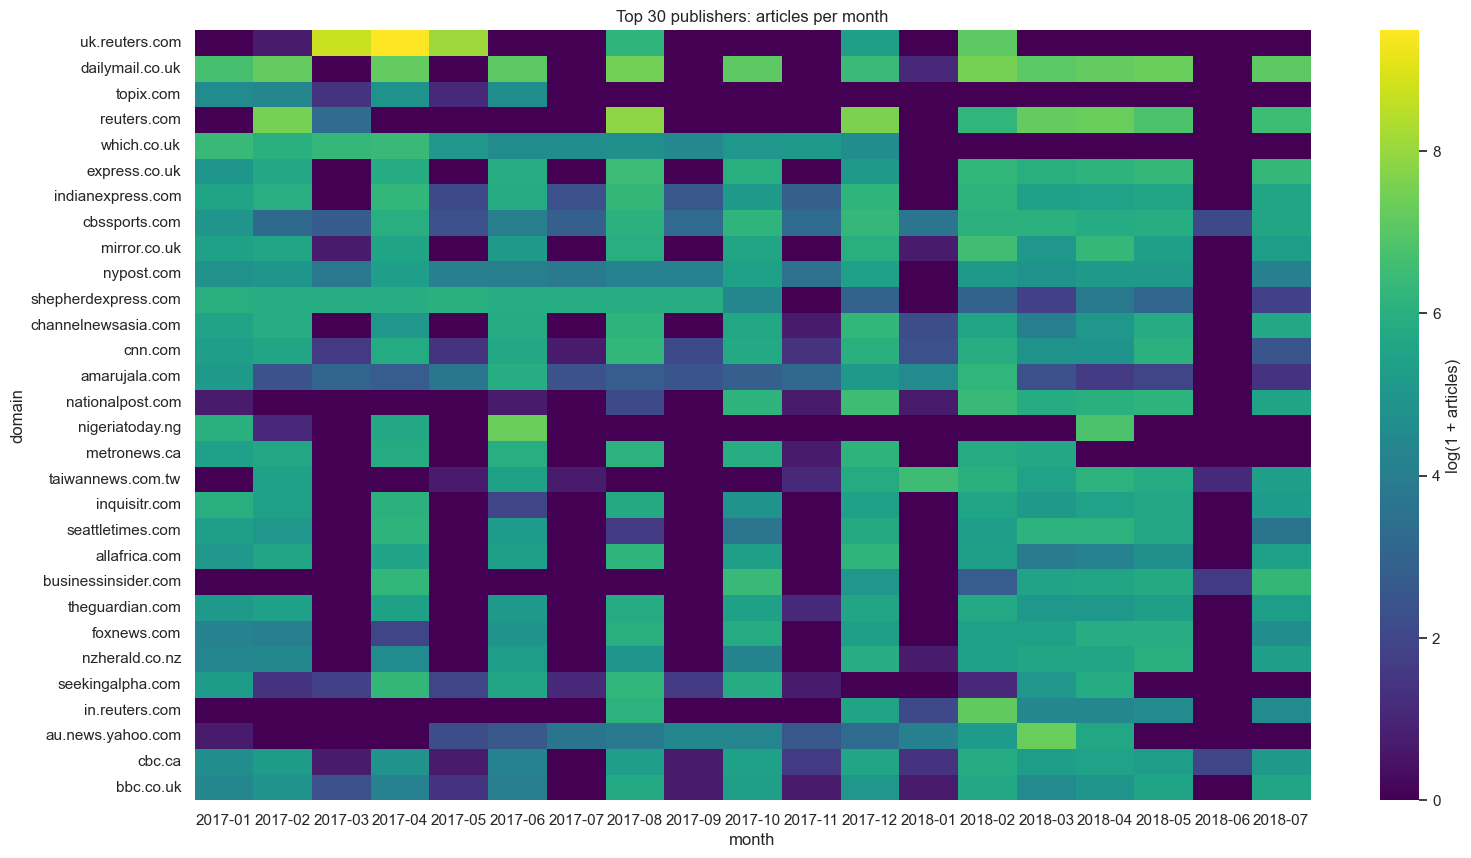

In [22]:
top = per_domain.head(TOP_N).index
cov = df[df['domain'].isin(top)].pivot_table(index='domain', columns='month', values='url', aggfunc='count').reindex(top)

plt.figure(figsize=(18, 10))
sns.heatmap(np.log1p(cov.fillna(0)), cmap='viridis', cbar_kws={'label': 'log(1 + articles)'})
plt.title(f'Top {TOP_N} publishers: articles per month')
plt.show()

**Interpretation.** The dark columns (2017-03/05/07/09/11, 2018-01/06) are months between snapshots and are empty for *every* outlet. They don't mean the outlet stopped publishing. Within the snapshot months:
- **Present in almost every snapshot:** dailymail, cbssports, nypost, cnn, cbc, bbc, theguardian, foxnews, nzherald, indianexpress, mirror
- **Short bursts:** uk.reuters.com (mostly Mar–May 2017), topix (H1 2017 only), which.co.uk (ends Dec 2017), nigeriatoday (5 months), businessinsider (mostly 2018)

**Chart:** keep only the snapshot-month columns, grey out zeros, and sort rows by coverage. The log colour scale is fine but needs the real counts on hover or as annotations.

In [23]:
n_months = df['month'].nunique()
span = df.groupby('domain').agg(
    n=('url', 'size'),
    first=('date', 'min'),
    last=('date', 'max'),
    active_months=('month', 'nunique'),
)
span['coverage'] = (span['active_months'] / n_months).round(2)
span['max_month_share'] = df.groupby(['domain', 'month']).size().groupby('domain').max() / span['n']  # burstiness
span.sort_values('n', ascending=False).head(TOP_N)

,n,first,last,active_months,coverage,max_month_share
domain,,,,,,
uk.reuters.com,24480,2017-02-12 17:55:24,2018-02-03 21:35:09,7,0.27,0.540482
dailymail.co.uk,15452,2017-01-01 19:34:40,2018-07-04 23:19:28,13,0.50,0.116231
topix.com,13354,2017-01-01 00:00:00,2017-06-30 00:00:00,6,0.23,0.009360
reuters.com,11378,2017-02-10 14:00:14,2018-07-04 22:20:07,9,0.35,0.230005
which.co.uk,7411,2017-01-02 00:00:00,2017-12-05 00:00:00,12,0.46,0.080826
express.co.uk,4875,2017-01-02 00:01:00,2018-07-04 22:24:00,12,0.46,0.131692
indianexpress.com,4151,2017-01-01 00:00:00,2018-07-06 00:00:00,16,0.62,0.126476
cbssports.com,4039,2017-01-01 00:00:00,2018-07-04 22:06:44,19,0.73,0.137410
mirror.co.uk,3791,2017-01-02 00:00:00,2018-07-04 22:00:34,14,0.54,0.191506


**Interpretation.** `coverage` divides by **26 calendar months**, including the empty months between snapshots and the 2019 stragglers. Even a perfect outlet can't get above about 0.73, which is why the §11 shortlist (`coverage >= 0.8`) comes out **empty**. Coverage has to be computed against the 13 snapshot months (§13).

`max_month_share` flags outlets that are bursty in time (one month holds most of their articles): in.reuters 0.56, uk.reuters 0.54, au.news.yahoo 0.65, nigeriatoday 0.49. A model trained on them learns one period, not the outlet.

## 6. Country / nationality of publishers
There is no country field. Proxy: country-code TLD (`.co.uk`, `.com.au`, `.in`, …). Generic TLDs (`.com`, `.net`, `.org`) are ambiguous, so fill `MANUAL_COUNTRY` by hand for the top `.com` domains.

In [24]:
TLD_COUNTRY = {
    'uk': 'UK', 'au': 'Australia', 'ca': 'Canada', 'in': 'India', 'ie': 'Ireland',
    'nz': 'New Zealand', 'za': 'South Africa', 'ng': 'Nigeria', 'ke': 'Kenya', 'gh': 'Ghana',
    'pk': 'Pakistan', 'ph': 'Philippines', 'sg': 'Singapore', 'my': 'Malaysia', 'hk': 'Hong Kong',
    'us': 'US', 'de': 'Germany', 'fr': 'France', 'jp': 'Japan', 'cn': 'China', 'ae': 'UAE',
}
MANUAL_COUNTRY = {
    # fill from the top-publisher list above, e.g. 'nytimes.com': 'US',
}

def country_of(domain):
    if domain in MANUAL_COUNTRY:
        return MANUAL_COUNTRY[domain]
    return TLD_COUNTRY.get(domain.rsplit('.', 1)[-1], 'generic/unknown')

df['country'] = df['domain'].map(country_of)
df['tld'] = df['domain'].str.rsplit('.', n=1).str[-1]
df['tld'].value_counts().head(20)

tld
com    525215
uk      73666
org     18059
ca      16864
au      11717
net     11258
ng       7096
ie       5259
in       4116
nz       4021
pk       3862
za       3305
tw       3303
sg       1937
tv       1295
us       1288
az        929
am        846
fm        832
jp        818
Name: count, dtype: int64

In [25]:
# Top generic-TLD publishers that still need a manual country
df.loc[df['country'] == 'generic/unknown', 'domain'].value_counts().head(50)

domain
uk.reuters.com          24480
topix.com               13354
reuters.com             11378
indianexpress.com        4151
cbssports.com            4039
nypost.com               3646
shepherdexpress.com      3605
channelnewsasia.com      3462
cnn.com                  3403
amarujala.com            3395
nationalpost.com         3238
taiwannews.com.tw        3103
inquisitr.com            2873
seattletimes.com         2784
allafrica.com            2661
businessinsider.com      2656
theguardian.com          2610
foxnews.com              2432
seekingalpha.com         2339
in.reuters.com           2332
au.news.yahoo.com        2330
abcnews.go.com           2110
webnewswire.com          2073
dailybulletin.com        2060
nbcnews.com              2058
ft.com                   1989
usatoday.com             1980
therecord.com            1860
ctpost.com               1806
fox.com                  1805
eonline.com              1803
financialexpress.com     1802
newindianexpress.com     1799
for

**Interpretation.** `.com` covers **74% of articles** (525k), so the domain ending can't give the country for most of the corpus. The top `.com` list mixes:
- US: cnn, nypost, foxnews, usatoday, latimes
- India: indianexpress, firstpost, financialexpress, newindianexpress
- Canada: nationalpost, theglobeandmail, thespec, therecord
- Singapore: channelnewsasia
- Africa: allafrica

`.tv`, `.fm`, `.am` and `.az` are vanity endings, not countries. → Fill `MANUAL_COUNTRY` for the top ~100 publishers (≥ 35% of articles) and accept "unknown" for the tail.

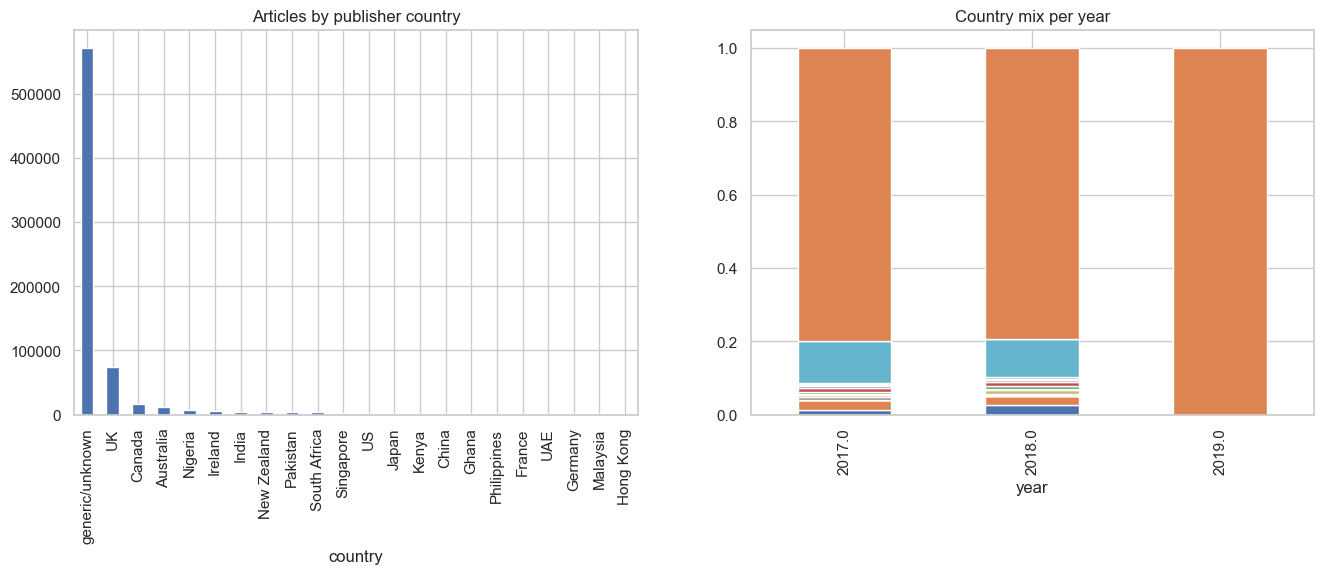

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
df['country'].value_counts().plot.bar(ax=ax[0], title='Articles by publisher country')
pd.crosstab(df['year'], df['country'], normalize='index').plot.bar(stacked=True, ax=ax[1], legend=False, title='Country mix per year')
plt.show()

**Interpretation.** About 80% is "generic/unknown", so the chart mostly shows the gap in the mapping. Among the known countries, the UK is by far the largest, followed by Canada and Australia. Once `.com` sites are mapped, the US will almost certainly dominate: an **Anglo, US/UK-centred corpus**.

**Chart:** show "unknown" separately (or exclude it). Use horizontal bars with % labels and a legend on the stacked chart, and drop the 2019 bar (2 articles).

In [27]:
# Language check: the dataset says English only. Verify on a sample (pip install langdetect)
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

lang_sample = df.sample(2000, random_state=0)
lang_sample['lang'] = lang_sample['text'].str[:1000].map(lambda t: detect(t) if t.strip() else 'empty')
lang_sample['lang'].value_counts()

lang
en    2000
Name: count, dtype: int64

**Interpretation.** 2,000/2,000 detected as English, but this is **misleading**. Detection ran on the body text, and the non-English sites (alquds.co.uk in Arabic, amarujala.com in Hindi) have English boilerplate as their text. Check the **title** script instead (§13).

## 7. Text characteristics per outlet
Length and field completeness differ by outlet. If one outlet's articles are always truncated, the model will learn that as its "style".

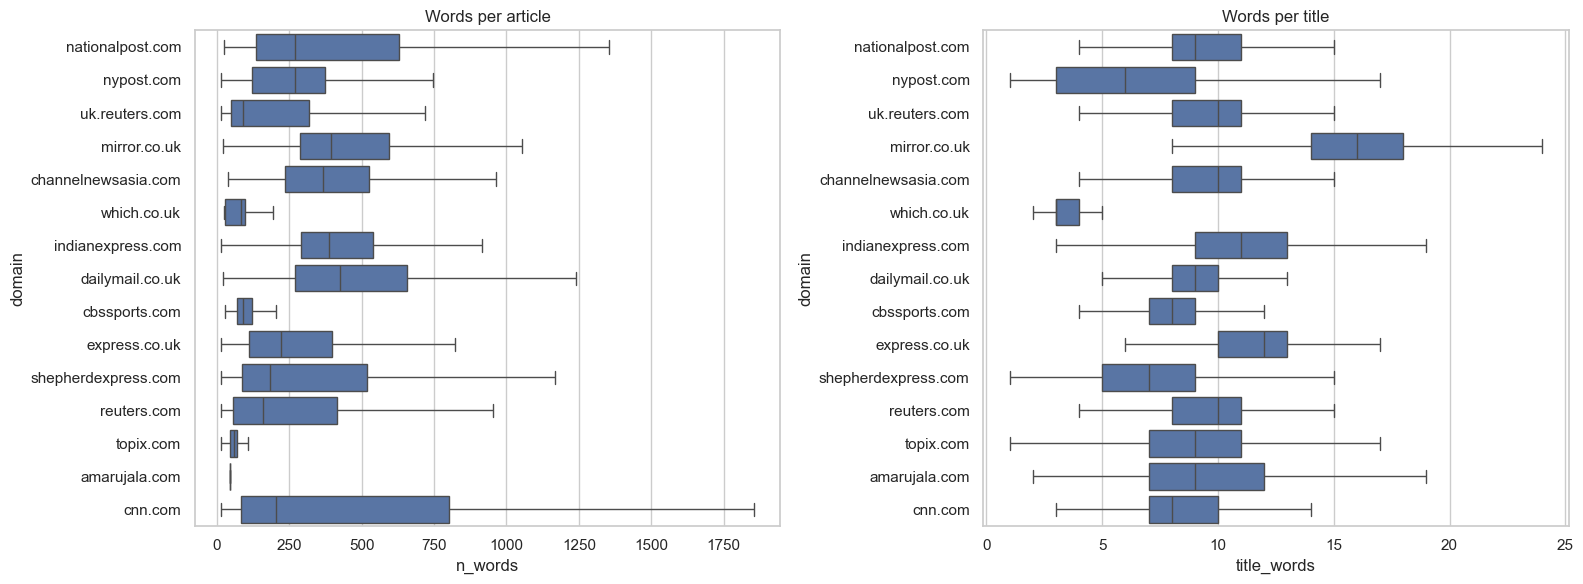

In [28]:
top_df = df[df['domain'].isin(per_domain.head(15).index)]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=top_df, y='domain', x='n_words', showfliers=False, ax=ax[0]).set(title='Words per article')
sns.boxplot(data=top_df, y='domain', x='title_words', showfliers=False, ax=ax[1]).set(title='Words per title')
plt.tight_layout(); plt.show()

**Interpretation.** Length is a strong outlet signal:
- **Long-form:** theguardian, dailymail, mirror (medians around 400–650 words)
- **Wide spread:** cnn (short video pages next to long features)
- **Tiny, nearly constant:** topix, which, cbssports, amarujala. These are not articles.

Headline length differs too: mirror ~16 words, nypost ~6, a clear style marker the generator should reproduce.

**Chart:** sort outlets by median and add `n` to each label. Drop the outlets that §13 removes so the axis isn't wasted on them.

In [29]:
nonempty = lambda s: s.fillna('').str.strip().ne('')
completeness = df.assign(
    has_description=nonempty(df['description']),
    has_image=nonempty(df['image_url']),
    short_text=df['n_words'] < 100,
).groupby('domain')[['has_description', 'has_image', 'short_text']].mean()
completeness.loc[per_domain.head(TOP_N).index].round(2)

,has_description,has_image,short_text
domain,,,
uk.reuters.com,1.00,1.0,0.52
dailymail.co.uk,1.00,1.0,0.04
topix.com,0.00,1.0,0.96
reuters.com,1.00,1.0,0.41
which.co.uk,1.00,1.0,0.92
express.co.uk,1.00,1.0,0.16
indianexpress.com,1.00,1.0,0.02
cbssports.com,1.00,1.0,0.59
mirror.co.uk,1.00,1.0,0.01


**Interpretation.**
- `has_image` is 1.0 everywhere, probably a default share image, so it tells us nothing.
- `description` is missing for all of topix and 46% of nypost.
- `short_text` (< 100 words) confirms the non-articles (amarujala 100%, topix 96%, which 92%). It also shows that **Reuters is often short** (uk.reuters 52%, reuters 41%) and so is au.news.yahoo (60%). Those are 50–100-word market briefs and wire snippets.

## 8. Topic proxy from the URL path
No topic label. Use the first non-numeric URL path segment (`/politics/…`, `/sport/…`) as a section proxy, then map sections to 4–5 shared topics later.

In [30]:
def section_of(url):
    for seg in urlparse(url).path.lower().split('/'):
        if seg and not seg.isdigit() and len(seg) < 25 and '-' not in seg and '.' not in seg:
            return seg
    return None

df['section'] = df['url'].map(section_of)
print('share with a section:', df['section'].notna().mean().round(3))
df['section'].value_counts().head(40)

share with a section: 0.673


section
news             132079
article           55389
story             24201
sport             17066
sports            16873
business           8714
wires              7586
articles           7389
entertainment      7058
directory          7038
world              6545
post               6340
city               6104
en                 5505
content            5299
politics           3959
opinion            3591
pmn                3533
fantasy            3424
events             3072
stories            2934
video              2892
a                  2888
lifestyle          2616
tvshowbiz          2076
us                 2036
watch              1931
sites              1777
music              1767
tag                1693
entry              1673
india              1659
philly             1565
videos             1553
national           1549
tv                 1524
soccer             1475
health             1454
football           1396
local              1353
Name: count, dtype: int64

**Interpretation.** 67% of URLs have a first path segment, but the most common are generic ("news", "article", "story", "post", "content", "en", "a") and say nothing about topic. Real topic segments (sport/sports, business, entertainment, politics, health, music, tv, soccer, football…) cover only a minority. "wires" (7,586) is Daily Mail's wire-copy section and should be treated as wire.

In [31]:
# Top sections per top outlet: is the section taxonomy usable for each one?
(df[df['domain'].isin(per_domain.head(10).index)]
   .groupby('domain')['section']
   .agg(lambda s: s.value_counts().head(8).to_dict()))

domain
cbssports.com                         {'fantasy': 3388, 'nfl': 203, 'nba': 144, 'mlb': 119, 'news': 74, 'soccer': 28, 'nhl': 21, 'golf': 20}
dailymail.co.uk      {'wires': 7585, 'news': 3082, 'tvshowbiz': 2076, 'sport': 1103, 'femail': 633, 'sciencetech': 290, 'money': 248, 'he...
express.co.uk        {'news': 1839, 'sport': 1725, 'showbiz': 298, 'entertainment': 187, 'finance': 163, 'life': 123, 'health': 95, 'trav...
indianexpress.com                                                             {'article': 4013, 'elections': 65, 'photos': 63, 'videos': 10}
mirror.co.uk                   {'news': 1422, 'sport': 1178, '3am': 418, 'tv': 404, 'money': 127, 'lifestyle': 76, 'tech': 65, 'travel': 37}
nypost.com                                                                         {'tag': 1680, 'horoscope': 51, 'video': 32, 'author': 26}
reuters.com                                                                                                   {'article': 11316, 'news': 62}
topix.

**Interpretation.**
- The UK tabloids (dailymail, express, mirror) have usable section taxonomies.
- reuters, uk.reuters and indianexpress are all "article", and nypost is "tag", so no topic can be read from their URLs.
- cbssports is 3,388 "fantasy".

→ The URL alone can't label topics for key outlets. Use the URL labels as training data for a classifier that labels the rest (§13).

## 9. Wire copy & cross-outlet duplication
AP/Reuters/AFP stories are republished by many outlets. They blur the per-outlet style signal and leak between train and test.

In [32]:
WIRE = r'\(AP\)|Associated Press|\(Reuters\)|Reuters|\(AFP\)|Agence France-Presse'
df['is_wire'] = df['text'].str[:400].str.contains(WIRE, regex=True, na=False)
print('wire share overall:', df['is_wire'].mean().round(3))
df.groupby('domain')['is_wire'].mean().loc[per_domain.head(TOP_N).index].sort_values(ascending=False).round(2)

wire share overall: 0.089


domain
in.reuters.com         0.95
reuters.com            0.80
seattletimes.com       0.79
taiwannews.com.tw      0.78
nzherald.co.nz         0.46
businessinsider.com    0.45
dailymail.co.uk        0.33
au.news.yahoo.com      0.20
uk.reuters.com         0.15
foxnews.com            0.07
indianexpress.com      0.06
channelnewsasia.com    0.04
bbc.co.uk              0.03
metronews.ca           0.02
nationalpost.com       0.02
seekingalpha.com       0.01
topix.com              0.01
inquisitr.com          0.01
theguardian.com        0.01
cbc.ca                 0.00
nypost.com             0.00
cnn.com                0.00
cbssports.com          0.00
nigeriatoday.ng        0.00
allafrica.com          0.00
express.co.uk          0.00
amarujala.com          0.00
which.co.uk            0.00
shepherdexpress.com    0.00
mirror.co.uk           0.00
Name: is_wire, dtype: float64

**Interpretation.** 8.9% of articles are flagged overall, but the flag mixes two things:
- **Reuters' own dateline:** "(Reuters)" in reuters.com (0.80) and in.reuters (0.95) is Reuters' own style, not copied text. The agency's own domains must not be flagged. This bug also removes most of Reuters from §10.
- **Real republishers:** seattletimes 0.79, taiwannews 0.78, nzherald 0.46, businessinsider 0.45, dailymail 0.33.

The regex also misses the AP footer seen in §2, so wire copy is **under-counted**. Fixed in §13.

In [33]:
# Same title published by several outlets
title_spread = df.groupby('title')['domain'].nunique()
print('titles shared by >1 outlet:', (title_spread > 1).sum())
title_spread.sort_values(ascending=False).head(20)

titles shared by >1 outlet: 38329


title
T.O. van attack suspect charged                                                          85
FAA Investigating After Harrison Ford Flies Over Jetliner Awaiting Takeoff               81
Suspect Arrested In Death Of N. Korean Dictator's Half-Brother                           81
N. Korean Leader Kim Jong Un's Half-Brother Is Dead. But Why?                            81
Man To Plead Guilty To Buying Weapons Used In San Bernardino Attack                      81
The Perplexing Psychology Of Saving For Health Care                                      80
Reports: U.S. Intercepted Calls Between Trump Campaign Staff And Russian Intelligence    77
Indian IT Outsourcers Anxious Over Potential Changes To H1-B Visas                       75
How To Get $20,000 Off The Price Of A Master's Degree                                    75
When Dating In The Era Of Divisive Politics, Both Sides Stick To Themselves              73
Zero tolerance for pot use with drivers: report                           

**Interpretation.** 38,329 titles appear on more than one outlet, one of them on 85. These are **syndication networks**: NPR-style feature headlines repeated across member stations, and the same Canadian local column across a chain ("Ont. towns struggle…", "Sousa's budgeting smoke and mirrors"). → These articles carry no outlet style. Remove them from per-outlet training, and keep same-story copies in the same train/test split.

Near-duplicate detection (MinHash, e.g. `datasketch`) is deferred to the preprocessing pipeline. Exact-title overlap above gives the order of magnitude.

## 10. Length reference for generation
Typical article length per outlet, and per outlet × topic, to use as a target when generating:
- in the prompt ("about N words"), or as a control token
- to set `max_tokens` (p90 words × ~1.3 tokens per word)
- in evaluation: compare the length distribution of generated articles with the real one

Computed on articles with ≥ 50 words and no wire copy. **No per-writer stats**: `vblagoje/cc_news` has no `author` column (`stanford-oval/ccnews` does).

In [34]:
# Exclude stubs and wire copy: they are not the outlet's own length
clean = df[(df['n_words'] >= 50) & ~df['is_wire']].copy()
clean['n_paragraphs'] = clean['text'].str.count('\n') + 1
clean['words_per_paragraph'] = clean['n_words'] / clean['n_paragraphs']

q = lambda p: (lambda s: s.quantile(p))
length_ref = clean.groupby('domain').agg(
    n=('n_words', 'size'),
    words_mean=('n_words', 'mean'),
    words_median=('n_words', 'median'),
    words_p10=('n_words', q(.10)),
    words_p25=('n_words', q(.25)),
    words_p75=('n_words', q(.75)),
    words_p90=('n_words', q(.90)),
    paragraphs_median=('n_paragraphs', 'median'),
    words_per_paragraph=('words_per_paragraph', 'median'),
    title_words_median=('title_words', 'median'),
).query('n >= 500').sort_values('n', ascending=False)

length_ref['max_tokens_hint'] = (length_ref['words_p90'] * 1.3).round(-1)  # ~1.3 tokens per English word
length_ref.head(TOP_N).round(1)

,n,words_mean,words_median,words_p10,words_p25,words_p75,words_p90,paragraphs_median,words_per_paragraph,title_words_median,max_tokens_hint
domain,,,,,,,,,,,
uk.reuters.com,15567,269.3,143.0,55.0,72.0,384.0,581.0,6.0,27.2,10.0,760.0
dailymail.co.uk,10123,598.9,488.0,234.0,341.0,716.0,1036.8,20.0,24.6,9.0,1350.0
topix.com,9192,69.2,65.0,53.0,57.0,76.0,90.0,2.0,32.5,9.0,120.0
express.co.uk,4861,280.3,224.0,91.0,111.0,398.0,530.0,6.0,35.3,12.0,690.0
which.co.uk,4064,145.1,96.0,91.0,96.0,96.0,177.7,1.0,96.0,3.0,230.0
indianexpress.com,3891,447.2,386.0,206.0,291.5,541.0,764.0,9.0,42.0,11.0,990.0
cbssports.com,3857,187.4,93.0,62.0,72.0,125.0,374.0,2.0,42.0,8.0,490.0
mirror.co.uk,3759,507.6,398.0,221.0,290.0,597.0,916.4,21.0,19.5,16.0,1190.0
channelnewsasia.com,3315,415.0,362.0,151.0,235.0,515.0,722.0,14.0,25.1,10.0,940.0


**Interpretation.**
- **Medians:** 65 words (topix) to 1,062 (seekingalpha). Mainstream newsrooms sit between 300 and 650.
- **Paragraph columns:** which.co.uk has 1 paragraph and nigeriatoday 9.6 words per paragraph, both extraction artefacts. They confirm the glued-paragraph problem in §1.
- **Reuters is under-represented** here because of the wire bug in §9.
- **`max_tokens_hint`:** seekingalpha needs 5,240 tokens, more than a small model's training context. Cap the training length (e.g. ≤ 1,500 words, or truncate at a paragraph boundary).

→ Recompute this table after cleaning, per publisher × topic (§13).

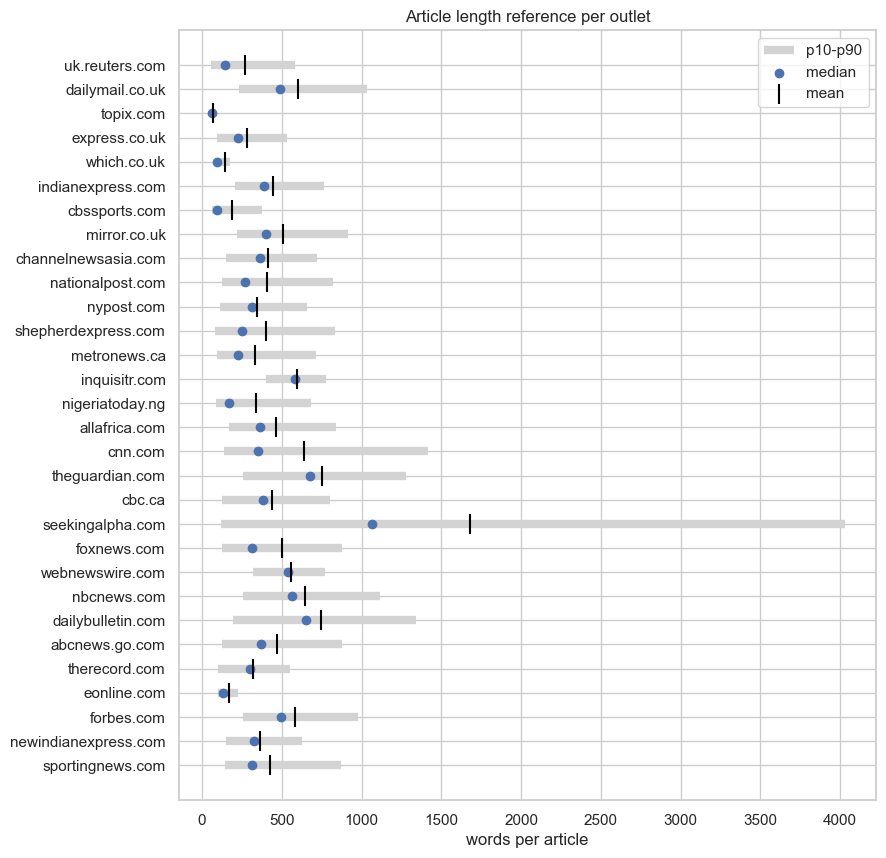

In [35]:
# Median length with the p10-p90 range, top outlets
r = length_ref.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 10))
ax.hlines(r.index, r['words_p10'], r['words_p90'], color='lightgray', lw=6, label='p10-p90')
ax.scatter(r['words_median'], r.index, zorder=3, label='median')
ax.scatter(r['words_mean'], r.index, marker='|', s=200, color='black', zorder=3, label='mean')
ax.set(xlabel='words per article', title='Article length reference per outlet')
ax.legend()
plt.show()

**Interpretation.** The mean is above the median for every outlet (right skew). → Use the **median as the length target** and p10–p90 as the acceptable range when evaluating generated text.

**Chart:** seekingalpha stretches the x-axis and squeezes everything else. Clip the axis at 2,000 words (or use log-x), sort by median, and grey out outlets that cleaning removes.

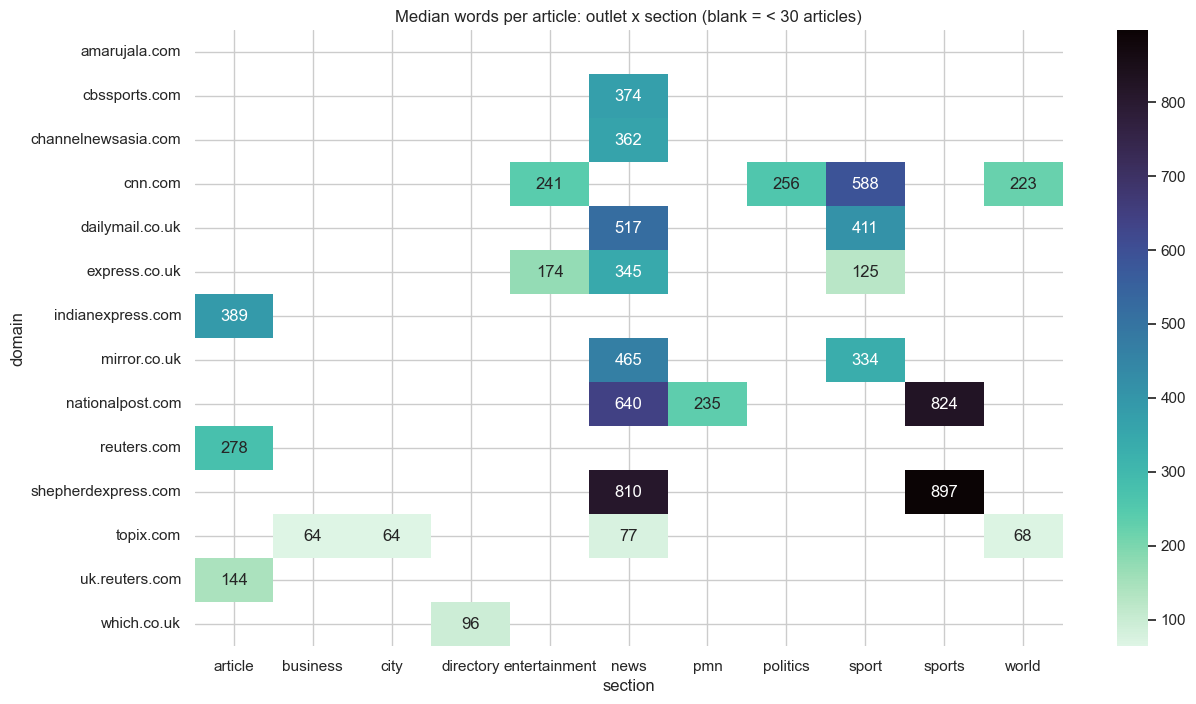

In [36]:
# Length also depends on topic (match reports vs. political analysis), and we condition on outlet AND topic.
# Median words per outlet x section, only cells with >= 30 articles.
top_outlets = per_domain.head(15).index
top_sections = clean['section'].value_counts().head(15).index
g = clean[clean['domain'].isin(top_outlets) & clean['section'].isin(top_sections)].groupby(['domain', 'section'])['n_words']
length_by_topic = g.median().where(g.size() >= 30).unstack()

plt.figure(figsize=(14, 8))
sns.heatmap(length_by_topic, annot=True, fmt='.0f', cmap='mako_r')
plt.title('Median words per article: outlet x section (blank = < 30 articles)')
plt.show()

**Interpretation.** Mostly empty: few outlet × section cells reach 30 articles, and the filled columns are generic ("news", "article"). Within an outlet, topic still changes length a lot (cnn sport 588 vs politics 256; express news 345 vs sport 125), which confirms that the length target should depend on **outlet and topic**. Redo this chart with classifier topics (§13).

In [37]:
length_ref.to_csv(OUT / 'length_reference.csv')
length_by_topic.to_csv(OUT / 'length_reference_by_section.csv')

## 11. Summary: biases & outlet shortlist

### Biases found
| Bias | Evidence (section) | Effect on the model | Mitigation |
|---|---|---|---|
| **Crawl snapshots, not continuous time** | §3: 72% of dated articles on ~15 days; ~12 snapshots | Date condition = ~12 periods; events between them unseen | Treat date as snapshot; test at snapshot dates |
| Missing dates | §1: 11% empty | Unusable for date conditioning | Drop |
| Duplicates & syndication | §2: 20% duplicated texts; §9: titles on up to 85 outlets | Same text learned as several outlets' style; train/test leakage | Dedupe; drop cross-outlet copies; split by story |
| Non-articles & non-English | §2, §4, §7: topix, which, amarujala, alquds, auto-generated finance | Noise learned as "news" | Drop by rule (§13) |
| Boilerplate | §2: subscribe prompts, cookie banners, AP footer | Boilerplate learned as outlet style | Strip before training |
| Publisher concentration / thin outlets | §4: Gini 0.83, only 96 publishers ≥ 1k | Few outlets have enough data; big ones dominate | Balanced sampling, 1–2k per outlet |
| Bursty outlets | §5: one month holds > 50% for some outlets | Outlet ≈ one period | Filter on `max_snapshot_share` |
| Country skew (US/UK) | §6: UK largest ccTLD; `.com` 74% unknown | "News" = Anglo framing | Report it; choose outlets on purpose |
| Missing timestamps | §3: 20.6% at 00:00:00 | Hour-level dates unreliable | Condition on day only |
| Wire copy | §9: up to 0.79 of some outlets; AP footer missed | Outlets look alike | Drop wire (agency's own domain exempt) |
| Sparse topic labels | §8: generic URL sections for key outlets | Topic condition noisy | URL map + classifier (§13.7) |
| Length differs by outlet/topic | §10 | Generated length off-target | Median target per outlet × topic |

The shortlist below is empty (see the interpretation). The working version is in §13.8.

In [38]:
outlet_stats = (
    span
    .join(df.groupby('domain').agg(
        country=('country', 'first'),
        median_words=('n_words', 'median'),
        wire_share=('is_wire', 'mean'),
        section_coverage=('section', lambda s: s.notna().mean()),
        n_sections=('section', 'nunique'),
    ))
    .join(completeness)
    .sort_values('n', ascending=False)
)
outlet_stats['lean_allsides'] = None   # fill by hand from AllSides / MBFC for the shortlist

# Shortlist criteria; adjust thresholds after looking at the numbers
shortlist = outlet_stats.query('n >= 5000 and coverage >= 0.8 and wire_share < 0.3 and median_words >= 200')
shortlist.head(20)

,n,first,last,active_months,coverage,max_month_share,country,median_words,wire_share,section_coverage,n_sections,has_description,has_image,short_text,lean_allsides
domain,,,,,,,,,,,,,,,


**Interpretation.** The shortlist is **empty** for two reasons:
1. `coverage` can't exceed ~0.73 (wrong denominator, see §5).
2. Only 5 publishers have `n >= 5000`, and they fail other filters.

§13 rebuilds it with merged publishers, coverage over the 13 snapshot months, and thresholds that fit the cleaned volumes.

In [39]:
outlet_stats.to_parquet(OUT / 'outlet_stats.parquet')
shortlist.to_csv(OUT / 'outlet_shortlist.csv')

## 12. What the EDA is still missing

In priority order for the project:

1. **Content and style per outlet.** Nothing yet looks *inside* the text. Add:
   - distinctive words per outlet (log-odds against the rest)
   - top n-grams
   - the stylometrics the evaluation will use: sentence length, quote rate, readability, first-person use, numbers per 100 words

   These real distributions are the baseline the generated text gets compared to.
2. **Topic distribution per outlet** (after §13 labels topics): outlet × topic counts, to know which cells can be balanced.
3. **Near-duplicates.** MinHash on a sample (e.g. 50k) to measure duplication beyond exact matches, plus which outlets share stories (syndication networks).
4. **Political lean coverage.** Join the candidate outlets with AllSides / MBFC ratings and check that the shortlist spans left–centre–right.
5. **What each snapshot covers.** Top entities and keywords per snapshot, to know which events the date condition can reproduce and to design the date-leakage test.
6. **Length in tokens of the chosen model**, not words, to fix the training sequence length.
7. **Text-quality artefacts.** Broken encoding (`â€™`), leftover HTML, URLs, emails, and how much of each outlet is affected.
8. **Feasibility of the train/test split.** Articles per outlet per snapshot *after* cleaning, to confirm a time-based split leaves enough test data for every outlet.

## 13. Transformations and filtering

What has to change before the data can be used for fine-tuning. Nothing is deleted from the raw data: every rule sets a **flag**, a funnel shows how many rows each rule removes, and the result is saved with a `keep` column and a `drop_reason`.

| Step | Transformation / rule | Why (EDA evidence) |
|---|---|---|
| 13.1 | Merge subdomains into one `publisher` | Reuters split across 3 domains (§4) |
| 13.2 | Keep Jan 2017 – Jul 2018, tag the crawl `snapshot` | 11% no date, 13 snapshot months, nothing after Jul 2018 (§3) |
| 13.3 | Clean text: strip boilerplate, split glued paragraphs, remove the repeated title | Boilerplate in the thousands, "strikeout.A day" (§1, §2) |
| 13.4 | Drop: no date, out of window, non-English title, non-article pages/publishers, auto-generated finance, < 100 words | §2, §6, §7, §8 |
| 13.5 | Drop exact duplicates (text; publisher+title), keep the earliest | 20% duplicated texts (§2) |
| 13.6 | Drop wire copy (fixed regex, agency's own domain exempt) and cross-outlet syndication | §9 |
| 13.7 | **Add topic**: URL section → 5 topics, then a TF-IDF classifier trained on those labels for the rest | Sections generic for key outlets (§8) |
| 13.8 | Rebuild outlet stats and shortlist; length reference per publisher × topic | Empty shortlist (§11), length depends on topic (§10) |

Rules marked "inspect" are first guesses from the top-k lists. Check a sample of each flag before trusting it.

### 13.1 Publisher: merge subdomains

In [ ]:
MANUAL_MERGE = {'bbc.co.uk': 'bbc.com'}   # add pairs the rule below can't catch

def parent_of(d):
    parts = d.split('.')
    k = 3 if len(parts[-1]) == 2 and len(parts) > 2 and parts[-2] in {'co', 'com', 'org', 'net', 'ac', 'gov'} else 2
    return '.'.join(parts[-k:])

domains = set(df['domain'])
df['publisher'] = df['domain'].map(lambda d: parent_of(d) if parent_of(d) in domains else d).replace(MANUAL_MERGE)

print('publishers:', df['domain'].nunique(), '->', df['publisher'].nunique())
df.loc[df['domain'] != df['publisher'], ['domain', 'publisher']].value_counts().head(25)

### 13.2 Time window and crawl snapshots

In [ ]:
WINDOW = ('2017-01-01', '2018-07-31 23:59:59')
monthly_n = df.groupby('month').size()
SNAPSHOT_MONTHS = monthly_n[monthly_n >= 5000].index
print(len(SNAPSHOT_MONTHS), 'snapshot months:', [str(m) for m in SNAPSHOT_MONTHS])

df['snapshot'] = df['month'].where(df['month'].isin(SNAPSHOT_MONTHS))
df['flag_no_date'] = df['date'].isna()
df['flag_out_of_window'] = df['date'].notna() & ~df['date'].between(*WINDOW)

### 13.3 Text cleaning (transform, not drop)

In [ ]:
import re

# Boilerplate found in §2. Extend this list after inspecting more of the top openings/endings
BOILERPLATE = re.compile('|'.join([
    r'The video will start in \d+ Cancel',
    r'Get (?:[Dd]aily|celebs) updates directly to your inbox \+ Subscribe Thank you for subscribing!',
    r'Send to Email Address.*?Sorry, your blog cannot share posts by email\.',
    r'(?:Facebook\n)?Twitter\nWhatsApp\n(?:Email\n)?Google\nTumblr\nLinkedIn\nSkype\nPocket\nReddit\nPrint\nPinterest',
    r'Sign up for BREAKING NEWS Emails privacy policy Thanks for subscribing!',
]), flags=re.DOTALL)

df['text_clean'] = (
    df['text']
    .str.replace(BOILERPLATE, ' ', regex=True)
    # glued paragraphs: "strikeout.A day later" -> new line. ponytail: heuristic, also splits rare cases like "Mr.Smith"
    .str.replace(r'(?<=[a-z][.!?])(?=[A-Z][a-z])', '\n', regex=True)
    .str.strip()
)

# Title repeated as the first line of the text
first_line = df['text_clean'].str.split('\n', n=1).str[0].str.strip()
rep = first_line.eq(df['title'].str.strip()) & df['text_clean'].str.contains('\n')
df.loc[rep, 'text_clean'] = df.loc[rep, 'text_clean'].str.split('\n', n=1).str[1]
print('title repeated as first line:', rep.sum())

df['n_words_clean'] = df['text_clean'].str.split().str.len()
df['n_paragraphs_clean'] = df['text_clean'].str.count('\n') + 1

### 13.4 Drop rules: non-English, non-articles, auto-generated, too short

In [ ]:
# Non-English: title in Arabic, Devanagari, Cyrillic or CJK script (the body text is often English boilerplate)
df['flag_non_english'] = df['title'].str.contains(r'[؀-ۿऀ-ॿЀ-ӿ一-鿿]', regex=True, na=False)

# Non-article pages and publishers (inspect: first guesses from §2, §4, §8)
NON_ARTICLE_SECTIONS = {'directory', 'video', 'videos', 'watch', 'events', 'horoscope', 'photos', 'gallery'}
NON_NEWS_PUBLISHERS = {
    'topix.com',       # aggregator snippets, median 65 words
    'which.co.uk',     # consumer product directory
    'amarujala.com',   # Hindi site, text is only boilerplate
    'fox.com',         # TV network episode blurbs
    'prnewswire.com',  # press releases
}
df['flag_non_article'] = df['section'].isin(NON_ARTICLE_SECTIONS) | df['publisher'].isin(NON_NEWS_PUBLISHERS)

# Auto-generated finance (chaffeybreeze-style templates): drop whole publishers where most articles match
autogen_row = (df['text'].str[:600].str.contains(r'\((?:NASDAQ|NYSE|NYSEMKT|NYSEARCA|LON|TSE|TSX):\s?[A-Z.]+\)', regex=True, na=False)
               & df['text'].str[:600].str.contains(r'price target|rating', regex=True, na=False))
autogen_share = autogen_row.groupby(df['publisher']).mean()
AUTOGEN_PUBLISHERS = set(autogen_share[autogen_share > 0.5].index)
print('auto-generated finance publishers:', len(AUTOGEN_PUBLISHERS), sorted(AUTOGEN_PUBLISHERS)[:20])
df['flag_autogen'] = df['publisher'].isin(AUTOGEN_PUBLISHERS)

MIN_WORDS = 100
df['flag_too_short'] = df['n_words_clean'] < MIN_WORDS
df['flag_too_long'] = df['n_words_clean'] > 2000   # not dropped: truncate at a paragraph boundary when building training examples

### 13.5–13.6 Duplicates, wire copy, syndication
Duplicates are computed only among rows that pass the rules above, so we keep the earliest *usable* copy.

In [ ]:
base = ~df[['flag_no_date', 'flag_out_of_window', 'flag_non_english', 'flag_non_article', 'flag_autogen', 'flag_too_short']].any(axis=1)
order = df.loc[base].sort_values('date').index

df['flag_dup_text'] = False
df.loc[order, 'flag_dup_text'] = df.loc[order, 'text_clean'].duplicated().values
df['flag_dup_title'] = False
df.loc[order, 'flag_dup_title'] = df.loc[order, ['publisher', 'title']].duplicated().values

# Wire copy, fixed: AP footer added, the agency's own domains are not flagged
AGENCIES = {'reuters.com', 'apnews.com', 'afp.com'}
WIRE_HEAD = r'\(AP\)|Associated Press|\(Reuters\)|Reuters|\(AFP\)|Agence France-Presse'
AP_FOOTER = r'may not be published, broadcast, (?:re)?written,? or redistributed'
df['flag_wire'] = ((df['text'].str[:400].str.contains(WIRE_HEAD, regex=True, na=False)
                    | df['text'].str[-300:].str.contains(AP_FOOTER, regex=True, na=False)
                    | df['section'].eq('wires'))
                   & ~df['publisher'].isin(AGENCIES))

# Syndication: same title on more than one publisher (titles of >= 4 words, so "News" etc. don't count)
spread = df.loc[base].groupby('title')['publisher'].transform('nunique')
df['flag_syndicated'] = False
df.loc[base, 'flag_syndicated'] = (spread > 1) & df.loc[base, 'title'].str.split().str.len().ge(4)

### Removal funnel
Rules applied in order. Each row is charged to the first rule that removes it.

In [ ]:
RULES = ['flag_no_date', 'flag_out_of_window', 'flag_non_english', 'flag_non_article', 'flag_autogen',
         'flag_too_short', 'flag_dup_text', 'flag_dup_title', 'flag_wire', 'flag_syndicated']

df['keep'] = True
df['drop_reason'] = None
rows = []
for r in RULES:
    hit = df['keep'] & df[r]
    df.loc[hit, 'drop_reason'] = r.removeprefix('flag_')
    df.loc[hit, 'keep'] = False
    rows.append((r.removeprefix('flag_'), hit.sum(), df['keep'].sum()))

funnel = pd.DataFrame(rows, columns=['rule', 'removed', 'remaining'])
funnel['removed_pct'] = (funnel['removed'] / len(df) * 100).round(1)
funnel

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(funnel['rule'][::-1], funnel['removed'][::-1], color=ACCENT)
for y, (n, pct) in enumerate(zip(funnel['removed'][::-1], funnel['removed_pct'][::-1])):
    ax.text(n, y, f'  {n:,} ({pct}%)', va='center', fontsize=9)
ax.xaxis.set_major_formatter(thousands)
ax.set(title=f"Cleaning keeps {df['keep'].sum():,} of {len(df):,} articles", xlabel='articles removed')
save(fig, 'cleaning_funnel')
plt.show()

# Inspect: 5 random removed rows per rule
for r in funnel['rule']:
    print('====', r)
    print(df.loc[df['drop_reason'] == r, ['publisher', 'title']].sample(min(5, (df['drop_reason'] == r).sum()), random_state=0).to_string())

### 13.7 Add a topic to every article
1. **URL section → topic** with a hand-made map (5 shared topics; edit the map, not the code).
2. **Classifier for the rest:** TF-IDF + logistic regression trained on the URL-labelled articles. Training is capped per publisher × topic, and evaluation uses **held-out publishers**, so the model learns topic rather than outlet style.
3. Predictions below 0.6 confidence → `other`.

**Validate by hand** on about 200 random articles before trusting the labels. A zero-shot or embedding model is the upgrade if accuracy is poor.

In [ ]:
TOPIC_MAP = {
    'politics': 'politics', 'election': 'politics', 'elections': 'politics', 'government': 'politics',
    'business': 'business', 'money': 'business', 'finance': 'business', 'markets': 'business', 'economy': 'business', 'companies': 'business',
    'sport': 'sport', 'sports': 'sport', 'soccer': 'sport', 'football': 'sport', 'nfl': 'sport', 'nba': 'sport', 'mlb': 'sport',
    'nhl': 'sport', 'golf': 'sport', 'cricket': 'sport', 'tennis': 'sport', 'rugby': 'sport',
    'entertainment': 'entertainment', 'showbiz': 'entertainment', 'tvshowbiz': 'entertainment', 'celebrity': 'entertainment',
    'music': 'entertainment', 'tv': 'entertainment', 'movies': 'entertainment', 'film': 'entertainment', '3am': 'entertainment', 'arts': 'entertainment',
    'tech': 'science_tech', 'technology': 'science_tech', 'science': 'science_tech', 'sciencetech': 'science_tech', 'health': 'science_tech',
}
df['topic_url'] = df['section'].map(TOPIC_MAP)
kept = df[df['keep']]
print('kept articles with a URL topic:', kept['topic_url'].notna().mean().round(3))
kept['topic_url'].value_counts()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report

doc = lambda d: d['title'].fillna('') + ' ' + d['text_clean'].str[:2000]

labeled = (kept[kept['topic_url'].notna()]
           .sample(frac=1, random_state=0)
           .groupby(['publisher', 'topic_url']).head(1000))   # cap so big outlets don't dominate
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(labeled, groups=labeled['publisher']))

vec = TfidfVectorizer(max_features=100_000, ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words='english')
clf = LogisticRegression(max_iter=2000, class_weight='balanced')
clf.fit(vec.fit_transform(doc(labeled.iloc[tr])), labeled['topic_url'].iloc[tr])
print(classification_report(labeled['topic_url'].iloc[te], clf.predict(vec.transform(doc(labeled.iloc[te])))))

In [ ]:
proba = clf.predict_proba(vec.transform(doc(kept)))
pred = np.where(proba.max(axis=1) >= 0.6, clf.classes_[proba.argmax(axis=1)], 'other')
df.loc[kept.index, 'topic'] = df.loc[kept.index, 'topic_url'].fillna(pd.Series(pred, index=kept.index))
kept = df[df['keep']]

print(kept['topic'].value_counts(normalize=True).round(3))
top_pub = kept['publisher'].value_counts().head(20).index
sub = kept[kept['publisher'].isin(top_pub)]
mix = pd.crosstab(sub['publisher'], sub['topic'], normalize='index').loc[top_pub]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(mix, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=ax)
ax.set(title='Topic mix per publisher (cleaned data)', xlabel='', ylabel='')
save(fig, 'topic_mix_per_publisher')
plt.show()

### 13.8 Outlet stats and shortlist on the cleaned data

In [ ]:
n_snap = len(SNAPSHOT_MONTHS)
kept = df[df['keep']].assign(country=lambda d: d['publisher'].map(country_of))
pub = kept.groupby('publisher').agg(
    n=('url', 'size'),
    snapshots=('snapshot', 'nunique'),
    median_words=('n_words_clean', 'median'),
    country=('country', 'first'),
)
pub['snapshot_coverage'] = (pub['snapshots'] / n_snap).round(2)
pub['max_snapshot_share'] = (kept.groupby(['publisher', 'snapshot']).size().groupby('publisher').max() / pub['n']).round(2)
topic_n = pd.crosstab(kept['publisher'], kept['topic'])
pub = pub.join(topic_n.add_prefix('n_'))
pub['min_topic_n'] = topic_n.drop(columns='other', errors='ignore').min(axis=1)
pub['lean_allsides'] = None   # fill by hand for the shortlist

# Thresholds sized to the cleaned volumes; adjust after looking at `pub`
shortlist = pub.query('n >= 1500 and snapshot_coverage >= 0.75 and max_snapshot_share <= 0.25').sort_values('n', ascending=False)
shortlist

In [ ]:
# Length reference per publisher x topic, on cleaned text (feeds the prompt length target)
g = kept.groupby(['publisher', 'topic'])['n_words_clean']
length_ref_topic = pd.DataFrame({
    'n': g.size(), 'median': g.median(), 'p10': g.quantile(.1), 'p90': g.quantile(.9),
}).query('n >= 30').round(0)
length_ref_topic.loc[shortlist.index.intersection(length_ref_topic.index.get_level_values(0))]

In [ ]:
pub.to_parquet(OUT / 'publisher_stats_clean.parquet')
shortlist.to_csv(OUT / 'outlet_shortlist.csv')
length_ref_topic.to_csv(OUT / 'length_reference_by_topic.csv')

cols = ['publisher', 'domain', 'date', 'snapshot', 'title', 'text_clean', 'url', 'section', 'topic',
        'n_words_clean', 'flag_too_long', 'keep', 'drop_reason']
df[cols].assign(snapshot=lambda d: d['snapshot'].astype(str)).to_parquet(OUT / 'cc_news_flagged.parquet')

## 14. Chart quality

**Rules for every chart** (defaults set in the cell after setup):
- **Title = the takeaway** ("Most articles fall in 13 crawl months"), not the variable name. Add `n` to the title or labels.
- **Thousands separators** on counts (`ax.yaxis.set_major_formatter(thousands)`) and **integer labels**. Drop missing dates before plotting, so `2017.0` / `1.0` disappear.
- **Sort** categorical bars by value. **One accent colour** for what matters (kept outlets, snapshot months) and grey for the rest. No unlabelled stacked colours.
- **Log scale** when values span orders of magnitude; clip or annotate outliers (seekingalpha) instead of letting them squash the axis.
- **No lines across gaps.** Months between snapshots are not data points.
- **Save** every figure the report uses with `save(fig, name)` → `reports/figures/`.

The per-chart fixes are listed under each interpretation above. Improved versions of the four weakest charts follow.

In [ ]:
# §3 monthly volume: bars, snapshot months highlighted, window only
m = df.loc[df['date'].between(*WINDOW), 'month'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(m.index.astype(str), m.values, color=[ACCENT if p in SNAPSHOT_MONTHS else MUTED for p in m.index])
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis='x', rotation=45)
ax.set(title=f'{len(SNAPSHOT_MONTHS)} crawl-snapshot months (blue) hold almost all articles', ylabel='articles')
save(fig, 'articles_per_month')
plt.show()

In [ ]:
# §3 hour of publication, without the 20.6% unknown (00:00:00) times
h = df.loc[df['date'].notna() & ~midnight, 'date'].dt.hour.astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(h.index, h.values, color=ACCENT)
ax.yaxis.set_major_formatter(thousands)
ax.set(title=f'Publication hour (timezone unknown; {midnight.mean():.0%} with no time excluded)', xlabel='hour', ylabel='articles', xticks=range(24))
save(fig, 'publication_hour')
plt.show()

In [ ]:
# §4 rank-frequency (replaces the broken log-log histogram)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(np.arange(1, len(per_domain) + 1), per_domain.values, '.', ms=3, color=ACCENT)
for k in (10, 100, 1000):
    ax.axvline(k, color=MUTED, lw=1, ls='--')
    ax.text(k, per_domain.max(), f' top {k}: {share.head(k).sum():.0%}', fontsize=8, va='top')
ax.set(title=f'{len(per_domain):,} publishers, only {(per_domain >= 1000).sum()} with ≥ 1,000 articles', xlabel='publisher rank', ylabel='articles')
save(fig, 'publisher_rank_frequency')
plt.show()

In [ ]:
# §4 top publishers after merging subdomains: raw vs kept after cleaning
p = df.groupby('publisher').agg(raw=('url', 'size'), kept=('keep', 'sum')).nlargest(TOP_N, 'raw').iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(p.index, p['raw'], color=MUTED, label='raw')
ax.barh(p.index, p['kept'], color=ACCENT, label='kept after cleaning')
ax.xaxis.set_major_formatter(thousands)
ax.legend(loc='lower right')
ax.set(title=f'Top {TOP_N} publishers: raw vs cleaned volume', xlabel='articles')
save(fig, 'top_publishers_raw_vs_clean')
plt.show()